# Okun's Law Across U.S. States, Rebuilt

**Sebastián Pedraza**

**Question:** does faster GDP growth lower unemployment by the same amount in every state?

Okun's Law says that when the economy grows faster than normal, unemployment falls. I first tested it for five states (Florida, New York, Washington, Alabama and South Dakota) in an undergraduate econometrics paper in 2024. That paper regressed the **level** of the unemployment rate on GDP growth and found almost nothing, with diagnostics that pointed to a misspecified model.

This notebook rebuilds the analysis in Python:

1. Replicate the 2024 model and show why it fails.
2. Test which series are stationary.
3. Estimate Okun's **difference** form (the change in unemployment on GDP growth) with standard errors that are robust to autocorrelation.
4. Check how much the COVID-19 shock drives the results.
5. Test formally whether the five states share one Okun coefficient.

## 1. Setup and data

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("src")
import okun

pd.set_option("display.float_format", "{:.3f}".format)

# Quarterly data, 2005-2022: unemployment rate (%) and real GDP for each state.
# To refresh from FRED, run `python src/fetch_fred.py` and change the path to data/fred_data.csv.
DATA_PATH = "data/original_2024_data.csv"

raw = okun.load_data(DATA_PATH)
df = okun.add_changes(raw)
print(df["state"].value_counts().sort_index().to_dict())
df.head()

{'AL': 72, 'FL': 72, 'NY': 72, 'SD': 72, 'WA': 72}


,state,date,unemp,real_gdp,g,du,g4,du4,covid
0,AL,2005-01-01,5.100,182600400000,NaN,NaN,NaN,NaN,False
1,AL,2005-04-01,4.267,184625700000,1.109,-0.833,NaN,NaN,False
2,AL,2005-07-01,4.367,184134900000,-0.266,0.100,NaN,NaN,False
3,AL,2005-10-01,4.033,186116900000,1.076,-0.333,NaN,NaN,False
4,AL,2006-01-01,4.333,186539000000,0.227,0.300,2.157,-0.767,False


Each row is one state in one quarter. `add_changes` builds the variables Okun's Law needs:

| Variable | Meaning |
|---|---|
| `g` | real GDP growth vs. the previous quarter, % |
| `du` | change in the unemployment rate vs. the previous quarter, percentage points |
| `g4` | real GDP growth vs. the same quarter a year earlier, % |
| `du4` | change in the unemployment rate vs. a year earlier, points |

## 2. Replicating the 2024 model

The original paper estimated, for each state:

$$U_t = \beta_0 + \beta_1 \, g_t + e_t$$

where $U_t$ is the unemployment **level** and $g_t$ is quarterly GDP growth. The numbers below should match the paper.

In [2]:
level = okun.run_state_models(df, y="unemp", x="g", model_name="2024 level model", hac=False)
level[["state", "okun_coef", "p_value", "r2", "durbin_watson", "n"]]

,state,okun_coef,p_value,r2,durbin_watson,n
0,AL,-0.254,0.159,0.029,0.173,71
1,FL,-0.363,0.059,0.051,0.211,71
2,NY,-0.143,0.302,0.015,0.387,71
3,SD,-0.010,0.845,0.001,0.526,71
4,WA,-0.268,0.049,0.055,0.444,71


These match the 2024 paper: R² is at most about 0.05, only Washington is significant at 5%, and the Durbin-Watson statistics (0.17 to 0.53) are far below 2.

**Why it fails:** the equation compares a slow-moving **level** (unemployment stays high or low for years) with a fast-moving **change** (growth jumps around quarter to quarter). Growth can't explain where the level sits, so R² is tiny, and the slow-moving level is left in the residuals, which is exactly what a very low Durbin-Watson statistic means. The chart shows the mismatch for Florida.

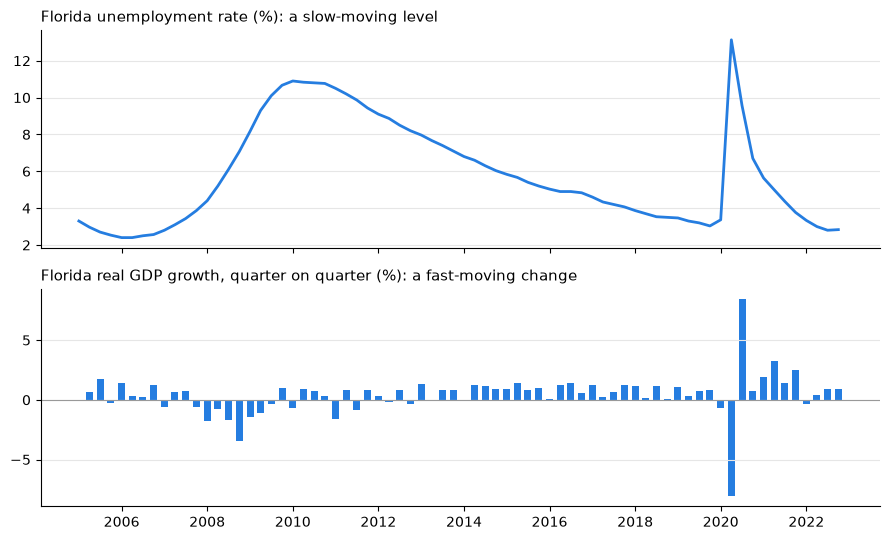

In [3]:
fl = df[df["state"] == "FL"]
fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
axes[0].plot(fl["date"], fl["unemp"], color="#257de0", linewidth=2)
axes[0].set_title("Florida unemployment rate (%): a slow-moving level", loc="left", fontsize=11)
axes[1].bar(fl["date"], fl["g"], width=60, color="#257de0")
axes[1].axhline(0, color="#999999", linewidth=0.8)
axes[1].set_title("Florida real GDP growth, quarter on quarter (%): a fast-moving change", loc="left", fontsize=11)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
fig.tight_layout()
fig.savefig("figures/fig1_level_vs_growth_florida.png", dpi=160)
plt.show()

## 3. Which series are stationary?

A regression on a non-stationary series (one that wanders without returning to a stable mean) can look meaningful when it isn't. The Augmented Dickey-Fuller test checks this: a **p-value below 0.05 means the series is stationary**.

In [4]:
okun.adf_table(df, ["unemp", "du", "g", "du4", "g4"])

,state,unemp,du,g,du4,g4
0,AL,0.394,0.000,0.000,0.329,0.207
1,FL,0.278,0.000,0.000,0.468,0.648
2,NY,0.037,0.000,0.000,0.270,0.001
3,SD,0.025,0.000,0.000,0.172,0.140
4,WA,0.024,0.000,0.000,0.278,0.326


Three things to read here:

- The unemployment **level** is not clearly stationary in Florida and Alabama (p well above 0.05).
- The **quarter-on-quarter** change in unemployment (`du`) and GDP growth (`g`) are stationary in every state (p ≈ 0.000). This is the cleanest basis for a regression, and it is what Okun's Law describes.
- The **year-over-year** versions (`du4`, `g4`) overlap from one quarter to the next, so they move slowly, and with only 18 years of data the test usually can't reject a unit root. I use them below because they cut quarterly noise, but I check every conclusion against the quarterly model, which has no such problem.

## 4. Okun's difference model

$$\Delta U_t = \alpha + \beta \, g_t + e_t$$

$\beta$ is the **Okun coefficient**: how many points unemployment moves when GDP grows one point faster. It should be negative. I use **Newey-West standard errors** (4 lags, one year of quarters), which stay valid when the errors are autocorrelated, the problem the 2024 paper ran into.

### 4a. Quarter on quarter

In [5]:
quarterly = okun.run_state_models(df, y="du", x="g", model_name="Quarterly, all quarters")
quarterly[["state", "okun_coef", "ci_low", "ci_high", "p_value", "r2", "durbin_watson"]]

,state,okun_coef,ci_low,ci_high,p_value,r2,durbin_watson
0,AL,-0.571,-0.720,-0.422,0.000,0.643,2.522
1,FL,-0.622,-0.909,-0.334,0.000,0.642,1.964
2,NY,-0.565,-1.035,-0.095,0.018,0.517,1.999
3,SD,-0.148,-0.353,0.056,0.156,0.224,2.457
4,WA,-0.579,-1.001,-0.157,0.007,0.494,2.101


Now every state has a negative coefficient and the Durbin-Watson statistics sit near 2, so the autocorrelation problem is gone. But 2020 is a huge outlier: GDP collapsed and unemployment jumped in a single quarter. Those few quarters can drive the whole fit, so the next step checks it.

### 4b. Year over year, with and without the COVID quarters

Quarterly state GDP is noisy, so the standard approach in state-level work is to compare each quarter with the same quarter a year earlier. I estimate it on all quarters and again **excluding 2020-2021**.

In [6]:
yoy_all = okun.run_state_models(df, y="du4", x="g4", model_name="Year over year, all quarters")
yoy_ex = okun.run_state_models(df, y="du4", x="g4", model_name="Year over year, excluding 2020-21", exclude_covid=True)
q_ex = okun.run_state_models(df, y="du", x="g", model_name="Quarterly, excluding 2020-21", exclude_covid=True)
results = pd.concat([yoy_all, yoy_ex])
results[["model", "state", "okun_coef", "ci_low", "ci_high", "p_value", "r2", "n"]]

,model,state,okun_coef,ci_low,ci_high,p_value,r2,n
0,"Year over year, all quarters",AL,-0.708,-0.839,-0.577,0.000,0.720,68
1,"Year over year, all quarters",FL,-0.545,-0.706,-0.385,0.000,0.674,68
2,"Year over year, all quarters",NY,-0.509,-0.942,-0.076,0.021,0.409,68
3,"Year over year, all quarters",SD,-0.118,-0.251,0.015,0.083,0.119,68
4,"Year over year, all quarters",WA,-0.472,-0.747,-0.197,0.001,0.394,68
0,"Year over year, excluding 2020-21",AL,-0.654,-0.919,-0.389,0.000,0.564,60
1,"Year over year, excluding 2020-21",FL,-0.419,-0.512,-0.325,0.000,0.680,60
2,"Year over year, excluding 2020-21",NY,0.014,-0.274,0.302,0.926,0.001,60
3,"Year over year, excluding 2020-21",SD,-0.020,-0.065,0.025,0.378,0.009,60
4,"Year over year, excluding 2020-21",WA,-0.238,-0.463,-0.012,0.039,0.306,60


**Check against the quarterly model.** Excluding 2020-21 in the quarterly (stationary) model as well, do the same states stand out?

In [7]:
q_ex[["state", "okun_coef", "ci_low", "ci_high", "p_value", "r2", "n"]]

,state,okun_coef,ci_low,ci_high,p_value,r2,n
0,AL,-0.310,-0.560,-0.059,0.015,0.146,63
1,FL,-0.238,-0.377,-0.099,0.001,0.359,63
2,NY,0.009,-0.065,0.082,0.817,0.001,63
3,SD,-0.013,-0.031,0.005,0.167,0.021,63
4,WA,-0.086,-0.205,0.033,0.155,0.103,63


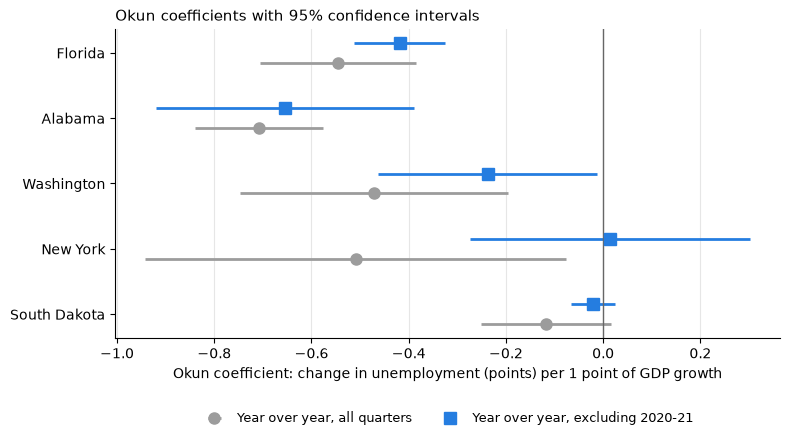

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.6))
order = ["FL", "AL", "WA", "NY", "SD"]
styles = {
    "Year over year, all quarters": dict(color="#9c9c9c", offset=0.15, marker="o"),
    "Year over year, excluding 2020-21": dict(color="#257de0", offset=-0.15, marker="s"),
}
for model, s in styles.items():
    r = results[results["model"] == model].set_index("state").loc[order]
    ypos = [i + s["offset"] for i in range(len(order))]
    ax.errorbar(r["okun_coef"], ypos,
                xerr=[r["okun_coef"] - r["ci_low"], r["ci_high"] - r["okun_coef"]],
                fmt=s["marker"], color=s["color"], markersize=8, linewidth=2, capsize=0, label=model)
ax.axvline(0, color="#666666", linewidth=1)
ax.set_yticks(range(len(order)), [okun.STATE_NAMES[s] for s in order])
ax.invert_yaxis()
ax.set_xlabel("Okun coefficient: change in unemployment (points) per 1 point of GDP growth")
ax.set_title("Okun coefficients with 95% confidence intervals", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e6e6e6", linewidth=0.8)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=9)
fig.tight_layout()
fig.savefig("figures/fig2_okun_coefficients.png", dpi=160)
plt.show()

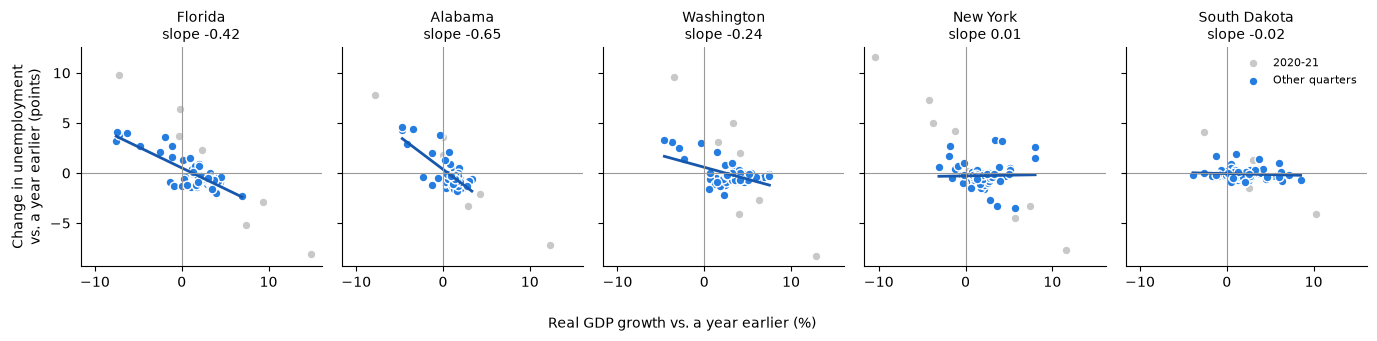

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3.4), sharex=True, sharey=True)
for ax, st in zip(axes, order):
    d = df[(df["state"] == st)].dropna(subset=["du4", "g4"])
    normal, shock = d[~d["covid"]], d[d["covid"]]
    ax.scatter(shock["g4"], shock["du4"], s=40, color="#c8c8c8", edgecolor="white", label="2020-21")
    ax.scatter(normal["g4"], normal["du4"], s=40, color="#257de0", edgecolor="white", label="Other quarters")
    fit = okun.fit_ols("du4 ~ g4", normal)
    xs = pd.Series([normal["g4"].min(), normal["g4"].max()])
    ax.plot(xs, fit.params["Intercept"] + fit.params["g4"] * xs, color="#1757ac", linewidth=2)
    ax.axhline(0, color="#999999", linewidth=0.8)
    ax.axvline(0, color="#999999", linewidth=0.8)
    ax.set_title(f"{okun.STATE_NAMES[st]}\nslope {fit.params['g4']:.2f}", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Change in unemployment\nvs. a year earlier (points)")
fig.supxlabel("Real GDP growth vs. a year earlier (%)", fontsize=10)
axes[-1].legend(frameon=False, fontsize=8, loc="upper right")
fig.tight_layout()
fig.savefig("figures/fig3_scatter_by_state.png", dpi=160)
plt.show()

## 5. Do the states share one Okun coefficient?

This was the paper's real question. I fit one pooled regression that lets each state have its own slope, then use a Wald test of the hypothesis that all five slopes are equal (year over year, excluding 2020-21, Newey-West errors).

In [10]:
stat, p, df_test = okun.test_equal_slopes(df, y="du4", x="g4", exclude_covid=True)
print(f"Wald test, all 5 slopes equal: chi2({df_test}) = {stat:.1f}, p = {p:.2g}")

Wald test, all 5 slopes equal: chi2(4) = 75.6, p = 1.5e-15


## 6. Findings

1. **The 2024 null result came from the model, not the economy.** Regressing the unemployment level on GDP growth explains almost nothing (R² ≤ 0.05) and leaves heavily autocorrelated residuals. The difference form, which is what Okun's Law actually describes, fixes both problems.
2. **Outside the pandemic, Okun's Law holds clearly only in Florida and Alabama.** Excluding 2020-21, one extra point of year-over-year GDP growth goes with unemployment about 0.42 points lower in Florida (R² ≈ 0.68) and 0.65 points lower in Alabama, and both stay significant in the quarterly model. Washington is borderline: significant year over year (−0.24, p ≈ 0.04) but not quarter on quarter.
3. **New York and South Dakota show no stable relationship outside the pandemic.** Their full-sample coefficients come almost entirely from 2020-21. A plausible reason for New York is that its GDP swings with finance, which moves output far more than jobs. South Dakota's unemployment is low and steady, with little room to move.
4. **The states do not share one coefficient.** The Wald test strongly rejects equal slopes, so a single national rule of thumb hides real differences between state economies.

## 7. Limitations

- **Simple bivariate model.** Five states, quarterly data, one explanatory variable. Explaining *why* states differ (industry mix, unionization, labor-market flexibility) would need those variables and more states.
- **Year-over-year changes are persistent.** They overlap, and the ADF test can't confirm they are stationary in this short sample. Newey-West errors handle the overlap, and the quarterly model, which is clearly stationary, points to the same conclusions.
- **The COVID window is a judgment call.** I report results with and without 2020-21 so the choice is visible.
- **Data vintage.** The data are my 2024 FRED download. Alabama's unemployment series in that file is not seasonally adjusted, while the others are; `src/fetch_fred.py` downloads seasonally adjusted series for all five states, and the results should be rerun on that refresh.
- **Associations, not causes.** Okun's Law is an empirical regularity, not a causal effect of growth on jobs.